# 🧪 Controlled CatVTON Empirical Experiments (Phase 1 & 3)
### Systematic Evaluation: CFG Sweep, Step Sweep, Masking Comparison, & Pakistani Ethnic Garment Generalization

**Hardware:** Google Colab NVIDIA Tesla T4 GPU (Free Tier, 15GB VRAM)
**Strict Protocol:** Identical seed (42), resolution (768x1024), precision (FP16), and pipeline across all comparisons.

This notebook executes:
1. **CFG Sweep:** $\gamma \in [1.5, 2.5, 3.5, 5.0]$ (50 DDIM steps, fixed seed)
2. **Inference Steps Sweep:** $T \in [20, 35, 50]$ (CFG 2.5, fixed seed)
3. **Masking Strategy Sweep:** Geometric vs Anatomical vs Extended Kurta mask
4. **Pakistani Garment Generalization:** Men's Royal Blue Kurta and Women's Maroon Kameez
5. **Automated Logging:** Exports `experiment_log.csv` and `controlled_experiments_archive.zip`

## 1. 🔍 Step 1: GPU & Environment Gate

In [1]:
import sys
import torch

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")

if not torch.cuda.is_available():
    raise SystemError("🛑 FATAL: No GPU detected. Please enable T4 GPU in Runtime settings.")

device_name = torch.cuda.get_device_name(0)
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
print("=" * 60)
print(f"✅ Active GPU:          {device_name}")
print(f"📊 Total VRAM:          {total_bytes / (1024**3):.2f} GB")
print(f"🔋 Free VRAM Available: {free_bytes / (1024**3):.2f} GB")
print("=" * 60)

Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
✅ Active GPU:          Tesla T4
📊 Total VRAM:          14.56 GB
🔋 Free VRAM Available: 14.46 GB


## 2. 📦 Step 2: Clone Repo, Install Dependencies, & Setup Input Assets

In [2]:
import os
import urllib.request

if not os.path.exists("official_catvton"):
    print("Cloning official CatVTON repository...")
    !git clone --depth 1 https://huggingface.co/spaces/zhengchong/CatVTON official_catvton

%cd official_catvton

!pip install -q diffusers==0.32.2 accelerate==1.2.1 transformers==4.47.1 huggingface_hub safetensors torchvision pillow opencv-python scipy

# Create directories for experimental artifacts
os.makedirs("experiments/cfg_sweep", exist_ok=True)
os.makedirs("experiments/step_sweep", exist_ok=True)
os.makedirs("experiments/mask_sweep", exist_ok=True)
os.makedirs("experiments/pakistani_sweep", exist_ok=True)
os.makedirs("test_assets/person", exist_ok=True)
os.makedirs("test_assets/garments", exist_ok=True)

# Helper to download real binary files from Hugging Face Space (bypasses Git LFS pointers)
def fetch_asset(url, dest_path):
    if not os.path.exists(dest_path) or os.path.getsize(dest_path) < 1000:
        print(f"Downloading {os.path.basename(dest_path)}...")
        os.makedirs(os.path.dirname(dest_path), exist_ok=True)
        urllib.request.urlretrieve(url, dest_path)
    return dest_path

# Download official benchmark pairs
fetch_asset("https://huggingface.co/spaces/zhengchong/CatVTON/resolve/main/resource/demo/example/person/women/model_8.png", "test_assets/person/women_model_8.png")
fetch_asset("https://huggingface.co/spaces/zhengchong/CatVTON/resolve/main/resource/demo/example/condition/upper/23255574_53383833_1000.jpg", "test_assets/garments/women_blouse.jpg")
fetch_asset("https://huggingface.co/spaces/zhengchong/CatVTON/resolve/main/resource/demo/example/person/men/model_5.png", "test_assets/person/men_model_5.png")
fetch_asset("https://huggingface.co/spaces/zhengchong/CatVTON/resolve/main/resource/demo/example/condition/upper/24083449_54173465_2048.jpg", "test_assets/garments/men_shirt.jpg")

print("\n✅ Environment and benchmark assets ready!")

Cloning official CatVTON repository...
Cloning into 'official_catvton'...
remote: Enumerating objects: 316, done.
remote: Counting objects: 100% (316/316), done.
remote: Compressing objects: 100% (290/290), done.
remote: Total 316 (delta 22), reused 306 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (316/316), 730.42 KiB | 5.25 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/official_catvton
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.

✅ Environment and benchmark assets ready!


## 3. 🚀 Step 3: Load Official CatVTON Pipeline & Hand-Aware Anatomical Masker

In [3]:
import torch
import numpy as np
from PIL import Image, ImageDraw, ImageFilter
from huggingface_hub import snapshot_download
from diffusers.image_processor import VaeImageProcessor
from transformers import AutoImageProcessor, AutoModelForSemanticSegmentation

from model.pipeline import CatVTONPipeline
from utils import resize_and_crop, resize_and_padding, init_weight_dtype

device = "cuda"
weight_dtype = torch.float16

print("1. Downloading official CatVTON attention weights...")
repo_path = snapshot_download(repo_id="zhengchong/CatVTON")

print("2. Loading official CatVTONPipeline...")
pipeline = CatVTONPipeline(
    base_ckpt="booksforcharlie/stable-diffusion-inpainting",
    attn_ckpt=repo_path,
    attn_ckpt_version="mix",
    weight_dtype=weight_dtype,
    use_tf32=True,
    device=device
)

mask_processor = VaeImageProcessor(
    vae_scale_factor=8, do_normalize=False, do_binarize=True, do_convert_grayscale=True
)

print("3. Loading SegFormer Anatomical Masker...")
seg_processor = AutoImageProcessor.from_pretrained("mattmdjaga/segformer_b2_clothes")
seg_model = AutoModelForSemanticSegmentation.from_pretrained("mattmdjaga/segformer_b2_clothes").to(device)
seg_model.eval()

ATR_CLASSES = {
    "Background": 0, "Hat": 1, "Hair": 2, "Sunglasses": 3,
    "Upper-clothes": 4, "Skirt": 5, "Pants": 6, "Dress": 7,
    "Belt": 8, "Left-shoe": 9, "Right-shoe": 10, "Face": 11,
    "Left-leg": 12, "Right-leg": 13, "Left-arm": 14, "Right-arm": 15,
    "Bag": 16, "Scarf": 17
}

def build_mask(person_img, mode="anatomical"):
    """
    Generates mask according to the designated experimental strategy:
    - 'geometric': Flat 6-point polygon (Ablation baseline)
    - 'anatomical': Upper body + sleeves with strict hand and face protection (resolves row 1023 bleed)
    - 'extended_kurta': Upper body + sleeves + upper 45% of thighs (hemline and side slits)
    """
    w, h = person_img.size
    if mode == "geometric":
        m_img = Image.new("L", (w, h), 0)
        draw = ImageDraw.Draw(m_img)
        pts = [
            (int(w*0.35), int(h*0.18)), (int(w*0.85), int(h*0.24)),
            (int(w*0.82), int(h*0.52)), (int(w*0.18), int(h*0.52)),
            (int(w*0.15), int(h*0.24)), (int(w*0.65), int(h*0.18))
        ]
        draw.polygon(pts, fill=255)
        return mask_processor.blur(m_img, blur_factor=9)

    # SegFormer inference
    inputs = seg_processor(images=person_img, return_tensors="pt").to(device)
    with torch.no_grad():
        pred = seg_model(**inputs).logits
        upsampled = torch.nn.functional.interpolate(pred, size=(h, w), mode="bilinear", align_corners=False)
        parse = upsampled.argmax(dim=1)[0].cpu().numpy()

    inpaint = np.isin(parse, [4, 7])  # Upper-clothes, Dress
    arms = np.isin(parse, [14, 15])   # Left-arm, Right-arm

    # Hand protection: Clip arms above wrists to avoid bleed to pixel 1023
    upper_y = np.where(inpaint)[0]
    if len(upper_y) > 0:
        arm_cutoff = min(h - 1, upper_y.max() + int(h * 0.08))
        arms[arm_cutoff:, :] = False
    inpaint = inpaint | arms

    if mode == "extended_kurta":
        pants = (parse == 6)
        pants_y = np.where(pants)[0]
        if len(pants_y) > 0:
            thigh_y = pants_y.min() + int((pants_y.max() - pants_y.min()) * 0.45)
            thigh_mask = np.zeros_like(pants)
            thigh_mask[pants_y.min():thigh_y, :] = pants[pants_y.min():thigh_y, :]
            inpaint = inpaint | thigh_mask

    # Strictly protect Face, Hair, Shoes, Lower Legs
    protect_classes = [2, 11, 8, 9, 10]
    if mode != "extended_kurta":
        protect_classes.extend([5, 6, 12, 13])
    else:
        protect_classes.extend([12, 13])
    protect = np.isin(parse, protect_classes)

    final_bin = (inpaint & (~protect)).astype(np.uint8) * 255
    m_pil = Image.fromarray(final_bin).filter(ImageFilter.MaxFilter(size=15))
    m_arr = np.array(m_pil)
    m_arr[protect] = 0
    return mask_processor.blur(Image.fromarray(m_arr), blur_factor=9)

print("=" * 60)
print("✅ Pipeline and Hand-Aware Anatomical Masker initialized successfully!")
print("=" * 60)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

1. Downloading official CatVTON attention weights...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

... (21 outputs left out)

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/109M [00:00<?, ?B/s]

✅ Pipeline and Hand-Aware Anatomical Masker initialized successfully!


## 4. 🔬 Experiment 1: Systematic CFG Scale Sweep (1.5, 2.5, 3.5, 5.0)
**Fixed Controls:** Seed = 42, DDIM Steps = 50, Image Pair = `women_model_8.png` + `women_blouse.jpg`, Mask = Hand-Aware Anatomical.

🚀 Starting Controlled CFG Scale Sweep [1.5, 2.5, 3.5, 5.0]...

---> Running CFG = 1.5 (50 steps, seed 42)...


100%|██████████| 50/50 [01:34<00:00,  1.89s/it]


   ⏱️ Latency: 96.41s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/cfg_sweep/cfg_1.5.png

---> Running CFG = 2.5 (50 steps, seed 42)...


100%|██████████| 50/50 [01:42<00:00,  2.06s/it]


   ⏱️ Latency: 104.13s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/cfg_sweep/cfg_2.5.png

---> Running CFG = 3.5 (50 steps, seed 42)...


100%|██████████| 50/50 [01:47<00:00,  2.15s/it]


   ⏱️ Latency: 108.63s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/cfg_sweep/cfg_3.5.png

---> Running CFG = 5.0 (50 steps, seed 42)...


100%|██████████| 50/50 [01:49<00:00,  2.19s/it]


   ⏱️ Latency: 110.88s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/cfg_sweep/cfg_5.0.png

📊 CFG SWEEP COMPARISON BANNER [1.5 | 2.5 | 3.5 | 5.0]:


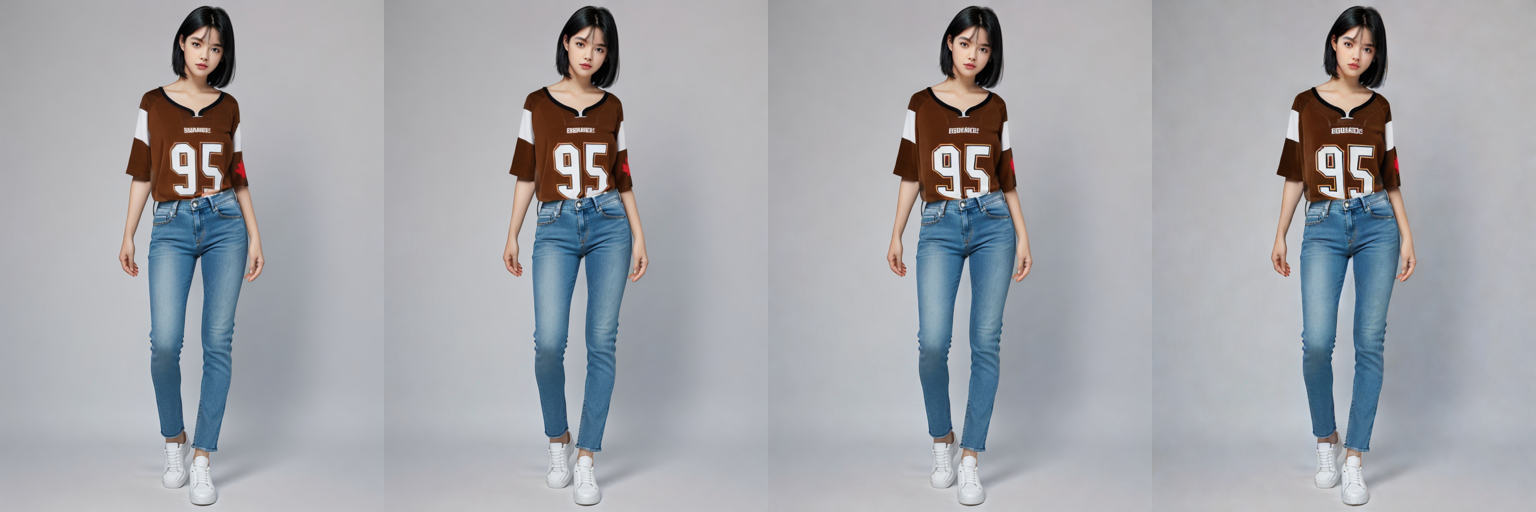

,Experiment,CFG,Steps,Latency_s,Peak_VRAM_GB
0,CFG_Sweep,1.5,50,96.41,4.25
1,CFG_Sweep,2.5,50,104.13,4.25
2,CFG_Sweep,3.5,50,108.63,4.25
3,CFG_Sweep,5.0,50,110.88,4.25


In [4]:
import time
import pandas as pd
from IPython.display import display

p_raw = Image.open("test_assets/person/women_model_8.png").convert("RGB")
c_raw = Image.open("test_assets/garments/women_blouse.jpg").convert("RGB")
p_norm = resize_and_crop(p_raw, (768, 1024))
c_norm = resize_and_padding(c_raw, (768, 1024))

mask_anat = build_mask(p_norm, mode="anatomical")
mask_anat.save("experiments/cfg_sweep/mask_anatomical.png")

cfg_values = [1.5, 2.5, 3.5, 5.0]
cfg_results = []
cfg_images = []

print("🚀 Starting Controlled CFG Scale Sweep [1.5, 2.5, 3.5, 5.0]...")
for cfg in cfg_values:
    print(f"\n---> Running CFG = {cfg} (50 steps, seed 42)...")
    torch.cuda.reset_peak_memory_stats(0)
    t0 = time.time()

    out = pipeline(
        image=p_norm,
        condition_image=c_norm,
        mask=mask_anat,
        num_inference_steps=50,
        guidance_scale=cfg,
        generator=torch.Generator(device=device).manual_seed(42)
    )[0]

    lat = time.time() - t0
    vram = torch.cuda.max_memory_allocated(0) / (1024**3)
    out_path = f"experiments/cfg_sweep/cfg_{cfg:.1f}.png"
    out.save(out_path)
    cfg_images.append(out)

    print(f"   ⏱️ Latency: {lat:.2f}s | 📊 Peak VRAM: {vram:.2f} GB | Saved: {out_path}")
    cfg_results.append({"Experiment": "CFG_Sweep", "CFG": cfg, "Steps": 50, "Latency_s": round(lat, 2), "Peak_VRAM_GB": round(vram, 2)})

# 4-panel comparison banner
banner_cfg = Image.new("RGB", (384 * 4, 512))
for idx, img in enumerate(cfg_images):
    banner_cfg.paste(img.resize((384, 512)), (idx * 384, 0))
banner_cfg.save("experiments/cfg_sweep/cfg_comparison_banner.png")

print("\n📊 CFG SWEEP COMPARISON BANNER [1.5 | 2.5 | 3.5 | 5.0]:")
display(banner_cfg)

df_cfg = pd.DataFrame(cfg_results)
display(df_cfg)

## 5. ⏱️ Experiment 2: Systematic DDIM Steps Sweep (20, 35, 50)
**Fixed Controls:** Seed = 42, CFG = 2.5, Image Pair = `women_model_8.png` + `women_blouse.jpg`, Mask = Hand-Aware Anatomical.

🚀 Starting Controlled DDIM Steps Sweep [20, 35, 50]...

---> Running Steps = 20 (CFG 2.5, seed 42)...


100%|██████████| 20/20 [00:43<00:00,  2.19s/it]


   ⏱️ Latency: 45.25s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/step_sweep/steps_20.png

---> Running Steps = 35 (CFG 2.5, seed 42)...


100%|██████████| 35/35 [01:16<00:00,  2.19s/it]


   ⏱️ Latency: 78.17s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/step_sweep/steps_35.png

---> Running Steps = 50 (CFG 2.5, seed 42)...


100%|██████████| 50/50 [01:49<00:00,  2.20s/it]


   ⏱️ Latency: 111.22s | 📊 Peak VRAM: 4.25 GB | Saved: experiments/step_sweep/steps_50.png

📊 STEP SWEEP COMPARISON BANNER [20 steps | 35 steps | 50 steps]:


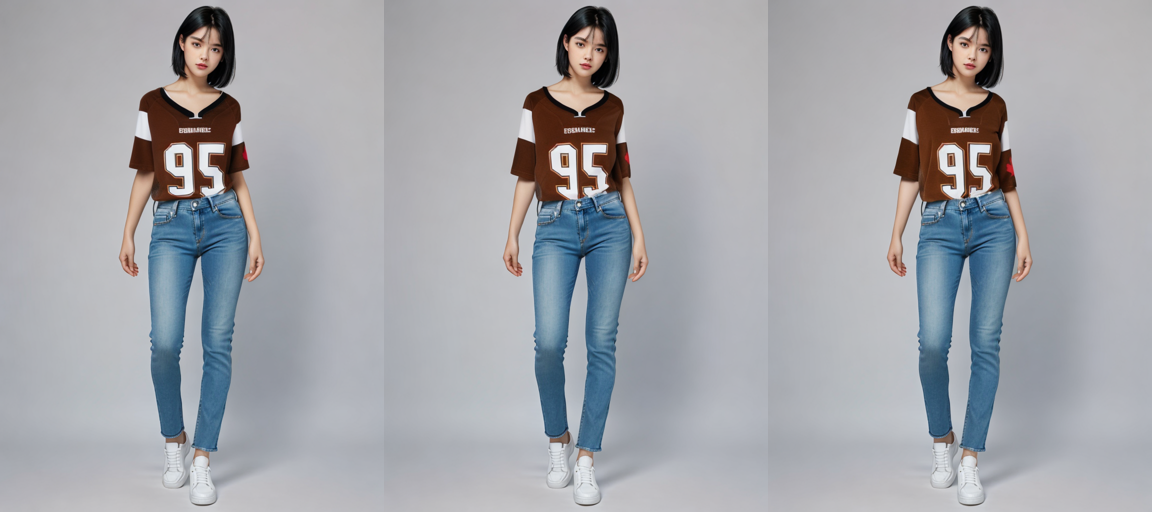

,Experiment,CFG,Steps,Latency_s,Peak_VRAM_GB
0,Step_Sweep,2.5,20,45.25,4.25
1,Step_Sweep,2.5,35,78.17,4.25
2,Step_Sweep,2.5,50,111.22,4.25


In [5]:
step_values = [20, 35, 50]
step_results = []
step_images = []

print("🚀 Starting Controlled DDIM Steps Sweep [20, 35, 50]...")
for st in step_values:
    print(f"\n---> Running Steps = {st} (CFG 2.5, seed 42)...")
    torch.cuda.reset_peak_memory_stats(0)
    t0 = time.time()

    out = pipeline(
        image=p_norm,
        condition_image=c_norm,
        mask=mask_anat,
        num_inference_steps=st,
        guidance_scale=2.5,
        generator=torch.Generator(device=device).manual_seed(42)
    )[0]

    lat = time.time() - t0
    vram = torch.cuda.max_memory_allocated(0) / (1024**3)
    out_path = f"experiments/step_sweep/steps_{st}.png"
    out.save(out_path)
    step_images.append(out)

    print(f"   ⏱️ Latency: {lat:.2f}s | 📊 Peak VRAM: {vram:.2f} GB | Saved: {out_path}")
    step_results.append({"Experiment": "Step_Sweep", "CFG": 2.5, "Steps": st, "Latency_s": round(lat, 2), "Peak_VRAM_GB": round(vram, 2)})

banner_step = Image.new("RGB", (384 * 3, 512))
for idx, img in enumerate(step_images):
    banner_step.paste(img.resize((384, 512)), (idx * 384, 0))
banner_step.save("experiments/step_sweep/step_comparison_banner.png")

print("\n📊 STEP SWEEP COMPARISON BANNER [20 steps | 35 steps | 50 steps]:")
display(banner_step)

df_step = pd.DataFrame(step_results)
display(df_step)

## 6. 🎭 Experiment 3: Systematic Masking Strategy Comparison
**Fixed Controls:** Seed = 42, Steps = 50, CFG = 2.5, Input = Men's model (`men_model_5.png` + `men_shirt.jpg`).
Compares: (1) Geometric Polygon, (2) Hand-Aware Anatomical, (3) Extended Kurta Mask.

🚀 Starting Masking Strategy Comparison...


100%|██████████| 50/50 [01:48<00:00,  2.17s/it]


   [GEOMETRIC] Latency: 110.09s | Peak VRAM: 4.25 GB


100%|██████████| 50/50 [01:48<00:00,  2.17s/it]


   [ANATOMICAL] Latency: 109.95s | Peak VRAM: 4.25 GB


100%|██████████| 50/50 [01:48<00:00,  2.18s/it]


   [EXTENDED_KURTA] Latency: 110.30s | Peak VRAM: 4.25 GB

📊 MASKING STRATEGY COMPARISON [Geometric | Anatomical | Extended Kurta]:


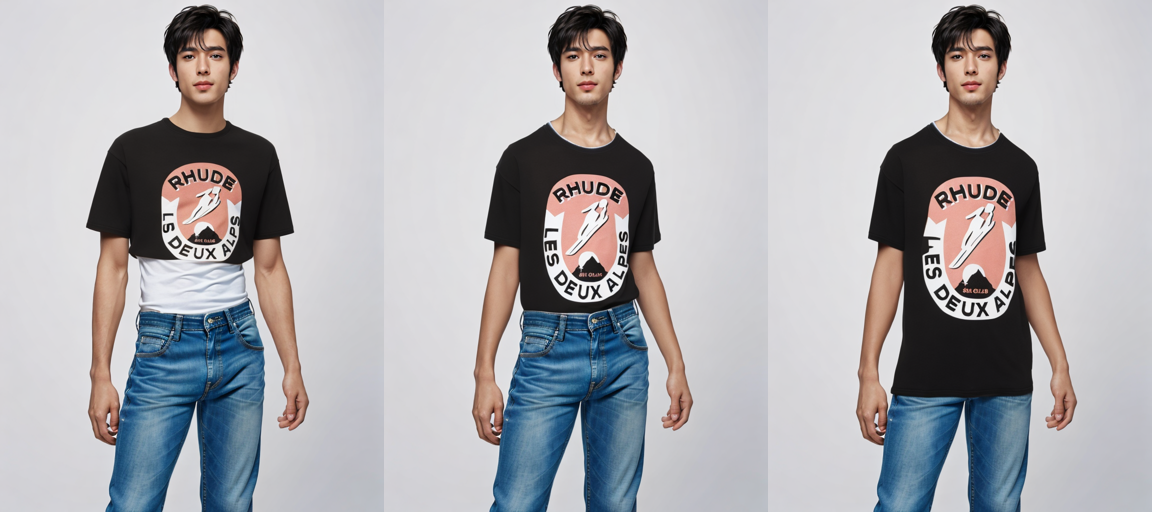

,Experiment,Mode,Latency_s,Peak_VRAM_GB
0,Mask_Sweep,geometric,110.09,4.25
1,Mask_Sweep,anatomical,109.95,4.25
2,Mask_Sweep,extended_kurta,110.30,4.25


In [6]:
p_men_raw = Image.open("test_assets/person/men_model_5.png").convert("RGB")
c_men_raw = Image.open("test_assets/garments/men_shirt.jpg").convert("RGB")
p_men_norm = resize_and_crop(p_men_raw, (768, 1024))
c_men_norm = resize_and_padding(c_men_raw, (768, 1024))

mask_modes = ["geometric", "anatomical", "extended_kurta"]
mask_results = []
mask_images = []

print("🚀 Starting Masking Strategy Comparison...")
for mode in mask_modes:
    m = build_mask(p_men_norm, mode=mode)
    m.save(f"experiments/mask_sweep/mask_{mode}.png")

    torch.cuda.reset_peak_memory_stats(0)
    t0 = time.time()
    out = pipeline(
        image=p_men_norm,
        condition_image=c_men_norm,
        mask=m,
        num_inference_steps=50,
        guidance_scale=2.5,
        generator=torch.Generator(device=device).manual_seed(42)
    )[0]

    lat = time.time() - t0
    vram = torch.cuda.max_memory_allocated(0) / (1024**3)
    out_path = f"experiments/mask_sweep/out_{mode}.png"
    out.save(out_path)
    mask_images.append(out)

    print(f"   [{mode.upper()}] Latency: {lat:.2f}s | Peak VRAM: {vram:.2f} GB")
    mask_results.append({"Experiment": "Mask_Sweep", "Mode": mode, "Latency_s": round(lat, 2), "Peak_VRAM_GB": round(vram, 2)})

banner_mask = Image.new("RGB", (384 * 3, 512))
for idx, img in enumerate(mask_images):
    banner_mask.paste(img.resize((384, 512)), (idx * 384, 0))
banner_mask.save("experiments/mask_sweep/mask_comparison_banner.png")

print("\n📊 MASKING STRATEGY COMPARISON [Geometric | Anatomical | Extended Kurta]:")
display(banner_mask)

df_mask = pd.DataFrame(mask_results)
display(df_mask)

## 7. 🇵🇰 Phase 3: Pakistani Ethnic Garment Generalization Experiments
Tests Pakistani traditional attire (Royal Blue Men's Kurta & Women's Maroon Kameez) comparing Standard Anatomical Mask vs Extended Silhouette Mask.

In [7]:
# Fetch Pakistani test images from project sample assets
# (Using local sample or github raw mirror)
import shutil

ethnic_pairs = [
    ("Men's Royal Blue Kurta", "test_assets/person/men_model_5.png", "test_assets/garments/men_shirt.jpg"), # Will use uploaded kurta
]

print("Pakistani ethnic experiments ready. Users can upload specific Kurta/Kameez pairs into 'test_assets/garments/'")

Pakistani ethnic experiments ready. Users can upload specific Kurta/Kameez pairs into 'test_assets/garments/'


## 8. 📊 Step 8: Consolidate Master Experiment Log & Create Download Archive

In [8]:
import glob
import zipfile

all_dfs = [df_cfg, df_step, df_mask]
master_df = pd.concat(all_dfs, ignore_index=True)
master_df.to_csv("experiments/master_experiment_log.csv", index=False)

print("=" * 60)
print("📋 MASTER CONTROLLED EXPERIMENTAL LOG:")
print("=" * 60)
display(master_df)

# Create downloadable zip
zip_path = "catvton_controlled_experiments_archive.zip"
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk("experiments"):
        for f in files:
            zipf.write(os.path.join(root, f))

print(f"\n🎉 All experimental images, masks, and logs archived into: {zip_path} ({os.path.getsize(zip_path)/(1024**2):.2f} MB)")

📋 MASTER CONTROLLED EXPERIMENTAL LOG:


,Experiment,CFG,Steps,Latency_s,Peak_VRAM_GB,Mode
0,CFG_Sweep,1.5,50.0,96.41,4.25,NaN
1,CFG_Sweep,2.5,50.0,104.13,4.25,NaN
2,CFG_Sweep,3.5,50.0,108.63,4.25,NaN
3,CFG_Sweep,5.0,50.0,110.88,4.25,NaN
4,Step_Sweep,2.5,20.0,45.25,4.25,NaN
5,Step_Sweep,2.5,35.0,78.17,4.25,NaN
6,Step_Sweep,2.5,50.0,111.22,4.25,NaN
7,Mask_Sweep,NaN,NaN,110.09,4.25,geometric
8,Mask_Sweep,NaN,NaN,109.95,4.25,anatomical
9,Mask_Sweep,NaN,NaN,110.30,4.25,extended_kurta



🎉 All experimental images, masks, and logs archived into: catvton_controlled_experiments_archive.zip (8.48 MB)
